<a href="https://colab.research.google.com/github/Dhivyadharshini3005/language-classifier/blob/main/fake_news_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

uploaded = files.upload()

Saving True.csv to True.csv
Saving Fake.csv to Fake.csv


In [3]:
import pandas as pd
import numpy as np
import re
import random
import pickle
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

fake_df = pd.read_csv("/content/Fake.csv")
true_df = pd.read_csv("/content/True.csv")

print("Fake dataset shape:", fake_df.shape)
print("Real dataset shape:", true_df.shape)
print("Libraries loaded successfully!")

Fake dataset shape: (23481, 4)
Real dataset shape: (21417, 4)
Libraries loaded successfully!


In [4]:
fake_df["label"] = 0
true_df["label"] = 1

df = pd.concat([fake_df, true_df], ignore_index=True)

print("Combined dataset:", df.shape)
display(df.head())

Combined dataset: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [5]:
df.columns = df.columns.str.lower().str.strip()

for col in ["title", "text"]:
    if col not in df.columns:
        df[col] = ""

df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

df["news"] = df["title"] + " " + df["text"]
df["news"] = df["news"].str.strip()

df = df[df["news"] != ""].copy()
df = df[["news", "label"]]
df = df.drop_duplicates(subset=["news"])

print("Missing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nCleaned dataset shape:", df.shape)

Missing values:
news     0
label    0
dtype: int64

Label distribution:
label
1    21196
0    17907
Name: count, dtype: int64

Cleaned dataset shape: (39103, 2)


In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["news"] = df["news"].apply(clean_text)

df = df[df["news"].str.len() > 0].reset_index(drop=True)

print("Text preprocessing completed!")
print("\nSample news:")
print(df["news"].iloc[0][:400])

Text preprocessing completed!

Sample news:
donald trump sends out embarrassing new year’s eve message; this is disturbing donald trump just couldn t wish all americans a happy new year and leave it at that. instead, he had to give a shout out to his enemies, haters and the very dishonest fake news media. the former reality show star had just one job to do and he couldn t do it. as our country rapidly grows stronger and smarter, i want to w


In [7]:
fake_news = df[df["label"] == 0]
real_news = df[df["label"] == 1]

n = min(1000, len(fake_news), len(real_news))

fake_sample = fake_news.sample(n=n, random_state=SEED)
real_sample = real_news.sample(n=n, random_state=SEED)

data = pd.concat([fake_sample, real_sample], ignore_index=True)

data = data.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("Total articles:", len(data))
print("\nClass distribution:")
print(data["label"].value_counts().rename(
    index={0: "Fake News", 1: "Real News"}
))

display(data.head())

Total articles: 2000

Class distribution:
label
Real News    1000
Fake News    1000
Name: count, dtype: int64


,news,label
0,"in georgia, costliest u.s. house race hits ugl...",1
1,watch chris christie awkwardly squirm in avoid...,0
2,u.s. appeals court questions scope of trump tr...,1
3,fbi: clinton foundation investigation will lea...,0
4,countdown to brexit breakthrough? brussels (re...,1


In [8]:
X = data["news"].values
y = data["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

Training articles: 1600
Testing articles: 400


In [9]:
MAX_WORDS = 20000
MAX_LENGTH = 400

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training sequence shape:", X_train_pad.shape)
print("Testing sequence shape:", X_test_pad.shape)
print("Vocabulary size:", len(tokenizer.word_index))

Training sequence shape: (1600, 400)
Testing sequence shape: (400, 400)
Vocabulary size: 29342


In [10]:
model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    Bidirectional(LSTM(32)),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 24s 444ms/step - accuracy: 0.7566 - loss: 0.6218 - val_accuracy: 0.8667 - val_loss: 0.4519
Epoch 2/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 18s 408ms/step - accuracy: 0.9581 - loss: 0.1821 - val_accuracy: 0.9833 - val_loss: 0.0625
Epoch 3/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 25s 514ms/step - accuracy: 0.9978 - loss: 0.0287 - val_accuracy: 0.9958 - val_loss: 0.0074
Epoch 4/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 36s 410ms/step - accuracy: 1.0000 - loss: 0.0055 - val_accuracy: 0.9958 - val_loss: 0.0043
Epoch 5/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 22s 444ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 0.9958 - val_loss: 0.0163
Epoch 6/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 18s 410ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.9958 - val_loss: 0.0132
Epoch 7/12
43/43 ━━━━━━━━━━━━━━━━━━━━ 17s 405ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.9958 - val_loss: 0.0117


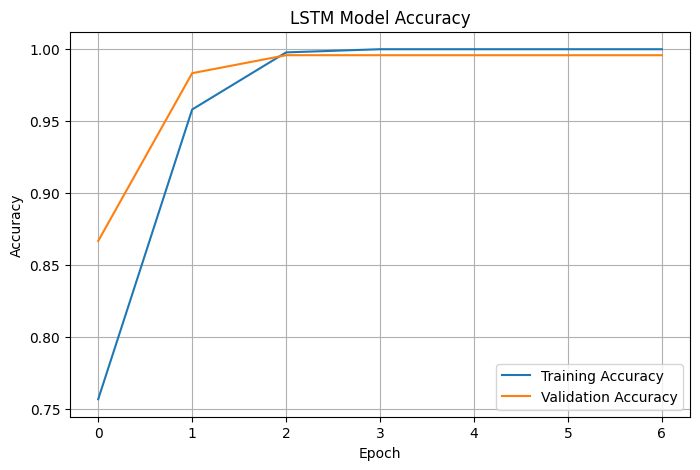

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
test_probabilities = model.predict(X_test_pad, verbose=0).ravel()

y_pred = (test_probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"],
    zero_division=0
))

Accuracy  : 99.50%
Precision : 0.9950
Recall    : 0.9950
F1 Score  : 0.9950

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      1.00      1.00       200
   Real News       1.00      0.99      0.99       200

    accuracy                           0.99       400
   macro avg       1.00      0.99      0.99       400
weighted avg       1.00      0.99      0.99       400



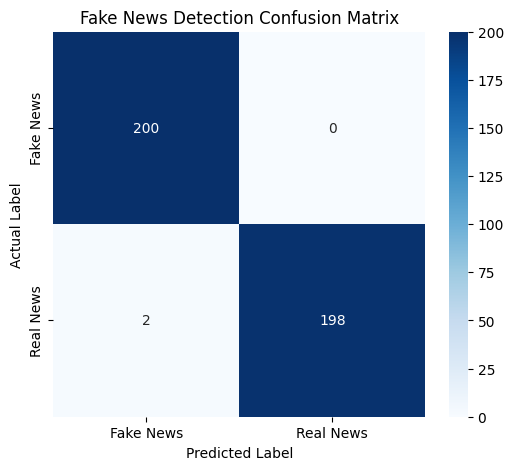

[[200   0]
 [  2 198]]


In [14]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fake News Detection Confusion Matrix")
plt.show()

print(cm)

In [15]:
def predict_news(news_text):
    cleaned = clean_text(news_text)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    probability_real = float(
        model.predict(padded, verbose=0)[0][0]
    )

    if probability_real >= 0.5:
        prediction = "REAL NEWS"
        confidence = probability_real * 100
    else:
        prediction = "FAKE NEWS"
        confidence = (1 - probability_real) * 100

    print("News:", news_text)
    print("Prediction:", prediction)
    print(f"Model score: {confidence:.2f}%")
    print("-" * 50)

predict_news(
    "The government announced a new public transport policy "
    "after a press conference on Monday."
)

predict_news(
    "A viral message claims that a secret drink makes people "
    "invisible overnight."
)

News: The government announced a new public transport policy after a press conference on Monday.
Prediction: REAL NEWS
Model score: 97.13%
--------------------------------------------------
News: A viral message claims that a secret drink makes people invisible overnight.
Prediction: FAKE NEWS
Model score: 96.60%
--------------------------------------------------


In [16]:
model.save("/content/fake_news_lstm.keras")

with open("/content/news_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [17]:
from google.colab import files

files.download("/content/fake_news_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
files.download("/content/news_tokenizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>